In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Simplified 2D example
word_embeddings={
    "cat": [0.8,0.6],
    "kitten": [0.75,0.65],
    "dog": [0.7,0.3],
    "puppy": [0.65,0.35],
    "car":[-0.5,0.2],
    "truck": [-0.45,0.15]
}


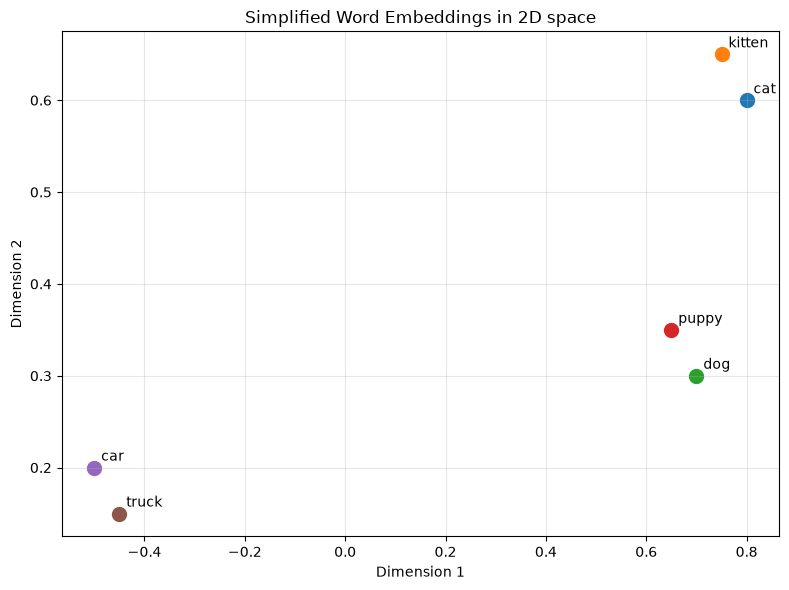

In [12]:
fig, ax = plt.subplots(figsize=(8, 6))

for word, coords in word_embeddings.items(): 
    ax.scatter(coords[0], coords[1], s=100)
    ax.annotate(word, (coords[0], coords[1]), xytext=(5,5),textcoords='offset points')
    
ax.set_xlabel ('Dimension 1') 
ax.set_ylabel('Dimension 2')
ax.set_title('Simplified Word Embeddings in 2D space') 
ax.grid(True, alpha=0.3)
plt.tight_layout ()
plt.show()

## Measuring Similarity

In [13]:
def cosine_similarity(vec1, vec2):
    """
    Cosine similarity measures the angle between two vectors.
    - Result close to 1: Very similar
    - Result close to 0: Not related
    - Result close to -1: Opposite meanings
    """

    dot_product=np.dot(vec1,vec2)
    norm_a=np.linalg.norm(vec1)
    norm_b=np.linalg.norm(vec2)
    return dot_product/(norm_a * norm_b)

In [14]:
# Example
cat_vector = [0.8, 0.6, 0.3]
kitten_vector = [0.75, 0.65, 0.35]
car_vector = [-0.5, 0.2, 0.1]

cat_kitten_similarity=cosine_similarity(cat_vector,kitten_vector)
print(cat_kitten_similarity)

0.9966186334192181


In [15]:
cat_car_similarity=cosine_similarity(cat_vector,car_vector)
print(cat_car_similarity)

-0.43718588548916804


## Creating your first Embeddings

In [17]:
### Huggingface and openAI Models
from langchain import embeddings
from langchain_huggingface import HuggingFaceEmbeddings

##initialize a simple Embedding model(no API Key needed!)
embeddings=HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)
embeddings

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2', cache_folder=None, model_kwargs={}, encode_kwargs={}, query_encode_kwargs={}, multi_process=False, show_progress=False)

In [19]:
##Create your first embeddings
text="Hello, I am learning about Embeddings"

embedding=embeddings.embed_query(text)
print(f"Text : {text}")
print(f"Embedding length : {len(embedding)}")
print(embedding)

Text : Hello, I am learning about Embeddings
Embedding length : 384
[-0.016661599278450012, -0.09771720319986343, 0.0019201452378183603, -0.0016135016921907663, 0.01404665783047676, 0.06083925440907478, 0.012283633463084698, 0.015745429322123528, 0.04093793034553528, -0.030124550685286522, 0.02626514993607998, 0.06559298932552338, 0.045701682567596436, 0.008897033520042896, -0.04620598629117012, 0.019462518393993378, 0.046773042529821396, 0.07357389479875565, -0.07927088439464569, -0.00660086702555418, -0.03383967652916908, -0.04663921520113945, 0.010644893161952496, -0.0967354103922844, 0.024105260148644447, -0.025332972407341003, -0.021411148831248283, 0.059114888310432434, 0.10023821890354156, -0.06024160608649254, 0.03970739245414734, -0.033746276050806046, -0.019574353471398354, 0.0662289634346962, -0.061764709651470184, 0.11689269542694092, 0.03955423831939697, -0.0030686173122376204, -0.08189611881971359, -0.0036541447043418884, 0.028080858290195465, 0.025156347081065178, -0.027

In [20]:
sentences = [
    "The cat sat on the mat",
    "A feline rested on the rug",
    "The dog played in the yard",
    "I love programming in Python",
    "Python is my favorite programming language"
]
embedding=embeddings.embed_documents(sentences)
print(f"Sentence : {sentences}")
print(f"Embedding length : {len(embedding)}")
print(embedding)

Sentence : ['The cat sat on the mat', 'A feline rested on the rug', 'The dog played in the yard', 'I love programming in Python', 'Python is my favorite programming language']
Embedding length : 5
[[0.1304018646478653, -0.011870133690536022, -0.028117060661315918, 0.05123867839574814, -0.05597445368766785, 0.030191591009497643, 0.030161259695887566, 0.02469836175441742, -0.018370574340224266, 0.05876678600907326, -0.024953175336122513, 0.06015428155660629, 0.039831776171922684, 0.03323052078485489, -0.061311379075050354, -0.04937313124537468, -0.054863497614860535, -0.040076062083244324, 0.05642908811569214, 0.03915657475590706, -0.034737102687358856, -0.013247696682810783, 0.031966228038072586, -0.06349923461675644, -0.06017860397696495, 0.07823451608419418, -0.028303861618041992, -0.047442834824323654, 0.04035928100347519, -0.0066309100948274136, -0.0667409673333168, -0.004191344138234854, -0.025311652570962906, 0.053341664373874664, 0.017428148537874222, -0.09792362153530121, 0.0060

## OpenAI Embedding Model